In [1]:
import re
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

RAW = Path("../data/raw/serpavi")
PROCESSED = Path("../data/processed")

excel = list(RAW.glob("*.xls*"))[0]
hoja = [h for h in pd.ExcelFile(excel).sheet_names if "ecci" in h.lower()][0]
serpavi = pd.read_excel(excel, sheet_name=hoja, dtype=str)
madrid = serpavi[serpavi["CUMUN"] == "28079"].copy()

anos = sorted({
    int(m.group(1)) for c in madrid.columns
    if (m := re.fullmatch(r"ALQM2_LV_M_VC_(\d{2})", c))
})
print("Secciones de Madrid:", len(madrid))
print("Años disponibles:", [2000 + a for a in anos])

Secciones de Madrid: 2442
Años disponibles: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


In [2]:
filas = []
for a in anos:
    col_precio = f"ALQM2_LV_M_VC_{a:02d}"
    col_n = f"BI_ALVHEPCO_TVC_{a:02d}"
    if col_n not in madrid.columns:
        print("Sin número de viviendas para", 2000 + a, "→ se salta")
        continue
    sub = madrid[["CUSEC", col_precio, col_n]].copy()
    sub.columns = ["cod_seccion_ine", "eur_m2", "n_viviendas"]
    sub["ano"] = 2000 + a
    filas.append(sub)

largo = pd.concat(filas, ignore_index=True)
largo[["eur_m2", "n_viviendas"]] = largo[["eur_m2", "n_viviendas"]].apply(pd.to_numeric, errors="coerce")
largo = largo.dropna(subset=["eur_m2", "n_viviendas"])
largo = largo[largo["n_viviendas"] > 0]

secciones = gpd.read_parquet(PROCESSED / "secciones.parquet")[["cod_seccion_ine", "cod_barrio"]]
largo = largo.merge(secciones, on="cod_seccion_ine")

largo["ponderado"] = largo["eur_m2"] * largo["n_viviendas"]
evolucion = largo.groupby(["cod_barrio", "ano"]).agg(
    ponderado=("ponderado", "sum"), n_viviendas=("n_viviendas", "sum")
).reset_index()
evolucion["eur_m2"] = (evolucion["ponderado"] / evolucion["n_viviendas"]).round(2)
evolucion = evolucion[["cod_barrio", "ano", "eur_m2", "n_viviendas"]]

# Madrid entero, para comparar
madrid_total = largo.groupby("ano").apply(
    lambda g: (g["eur_m2"] * g["n_viviendas"]).sum() / g["n_viviendas"].sum()
).round(2)
print("€/m² medio en Madrid por año:")
print(madrid_total.to_string())
print("\nBarrios con dato por año:")
print(evolucion.groupby("ano")["cod_barrio"].nunique().to_string())

evolucion.to_parquet(PROCESSED / "evolucion_alquiler.parquet")

€/m² medio en Madrid por año:
ano
2011    11.36
2012    11.11
2013    10.57
2014    10.34
2015    10.39
2016    10.60
2017    10.91
2018    11.40
2019    12.37
2020    12.62
2021    12.77
2022    13.24
2023    13.81
2024    14.50

Barrios con dato por año:
ano
2011    130
2012    130
2013    130
2014    130
2015    130
2016    130
2017    130
2018    131
2019    131
2020    131
2021    131
2022    131
2023    131
2024    131


In [3]:
# Percentiles 25 y 75 de 2024 por barrio (media ponderada de sus secciones)
p = madrid[["CUSEC", "ALQM2_LV_25_VC_24", "ALQM2_LV_75_VC_24", "BI_ALVHEPCO_TVC_24"]].copy()
p.columns = ["cod_seccion_ine", "p25", "p75", "n"]
p[["p25", "p75", "n"]] = p[["p25", "p75", "n"]].apply(pd.to_numeric, errors="coerce")
p = p.dropna().merge(secciones, on="cod_seccion_ine")
rango = p.groupby("cod_barrio").apply(
    lambda g: pd.Series({
        "eur_m2_p25": (g["p25"] * g["n"]).sum() / g["n"].sum(),
        "eur_m2_p75": (g["p75"] * g["n"]).sum() / g["n"].sum(),
    })
).round(2).reset_index()

# Tendencia: subida anual media de los últimos 5 años y estimación para 2026
tabla = evolucion.pivot(index="cod_barrio", columns="ano", values="eur_m2")
ultimo = max(tabla.columns)
base = ultimo - 5
subida_anual = (tabla[ultimo] / tabla[base]) ** (1 / 5) - 1

tendencia = pd.DataFrame({
    "cod_barrio": tabla.index,
    "subida_anual": subida_anual.round(4).values,
    f"subida_{base}_{ultimo}": (tabla[ultimo] / tabla[base] - 1).round(4).values,
    "eur_m2_estimado_2026": (tabla[ultimo] * (1 + subida_anual) ** (2026 - ultimo)).round(2).values,
})

economia = rango.merge(tendencia, on="cod_barrio", how="outer")
economia.to_parquet(PROCESSED / "barrios_economia.parquet")

# Los barrios que más han subido
barrios = gpd.read_parquet(PROCESSED / "barrios.parquet")[["cod_barrio", "barrio", "distrito"]]
vista = economia.merge(barrios, on="cod_barrio")
print(f"Barrios que más han subido ({base}–{ultimo}):")
print(vista.nlargest(10, f"subida_{base}_{ultimo}")[["barrio", "distrito", f"subida_{base}_{ultimo}", "subida_anual"]].to_string(index=False))
print(f"\nBarrios que menos han subido ({base}–{ultimo}):")
print(vista.nsmallest(5, f"subida_{base}_{ultimo}")[["barrio", "distrito", f"subida_{base}_{ultimo}", "subida_anual"]].to_string(index=False))

Barrios que más han subido (2019–2024):
                                         barrio           distrito  subida_2019_2024  subida_anual
                                   El Cañaveral          Vicálvaro            0.4613        0.0788
                                         Atocha         Arganzuela            0.4518        0.0774
                                     El Plantío  Moncloa - Aravaca            0.4326        0.0745
                                  San Cristóbal         Villaverde            0.3197        0.0571
                                     Aeropuerto            Barajas            0.2755        0.0499
Villaverde Alto - Casco Histórico de Villaverde         Villaverde            0.2440        0.0446
                                    Almendrales              Usera            0.2293        0.0421
                                        Ángeles         Villaverde            0.2280        0.0419
                                       Portazgo Puente de Vallecas   

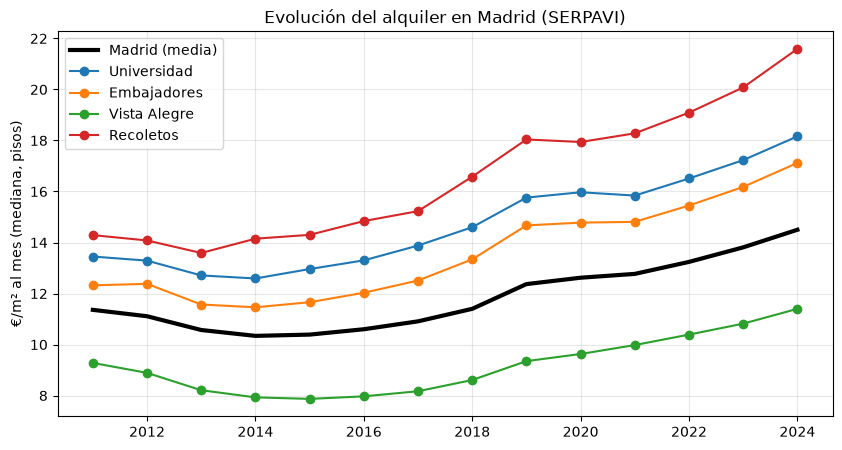

In [4]:
nombres = barrios.set_index("cod_barrio")["barrio"]
ejemplo = ["Universidad", "Embajadores", "Vista Alegre", "Recoletos"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(madrid_total.index, madrid_total.values, color="black", linewidth=3, label="Madrid (media)")
for b in ejemplo:
    serie = evolucion[evolucion["cod_barrio"].map(nombres) == b]
    ax.plot(serie["ano"], serie["eur_m2"], marker="o", label=b)
ax.set_ylabel("€/m² al mes (mediana, pisos)")
ax.set_title("Evolución del alquiler en Madrid (SERPAVI)")
ax.legend()
ax.grid(alpha=0.3)